# Segmentación de filamentos solares: baseline con visión clásica

MCD8012 Visión Computacional, Perfil de Proyecto.
Integrantes: Armando Canales, Diego Trujillo, Renato Miranda, Joshi Lopez y Piero Freundt.

Este notebook contiene el resultado preliminar del proyecto. Se implementa un método de segmentación basado en técnicas clásicas (umbralización, morfología y componentes conectadas) sobre las imágenes H-alfa del conjunto MAGFiLO, publicado en la competencia *Solar Filament Segmentation Challenge 2026* de Kaggle. El método se evalúa con Dice, IoU y Panoptic Quality (PQ), que es la métrica principal de la competencia.

Los datos deben estar en `../datos/MAGFiLO_1.0_Kaggle_2026`, con la estructura original de Kaggle.

## 1. Librerías y rutas

In [1]:
import csv
import json
import time
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from pycocotools import mask as mask_utils

RAIZ = Path('..') / 'datos' / 'MAGFiLO_1.0_Kaggle_2026'
DIR_TRAIN = RAIZ / 'train' / 'train_images'
JSON_TRAIN = RAIZ / 'train' / 'MAGFiLO_1.0_Annotations_kaggle2026_train.json'
DIR_TEST = RAIZ / 'test' / 'test_images'
DIR_RESULTADOS = Path('..') / 'resultados'
DIR_RESULTADOS.mkdir(exist_ok=True)

for p in (DIR_TRAIN, JSON_TRAIN, DIR_TEST):
    if not p.exists():
        raise FileNotFoundError(f'No se encontró {p.resolve()}')
print('Datos en', RAIZ.resolve())

Datos en C:\Users\Lenovo\Desktop\VISIÓN COMPUTACIONAL\PROYECTO_FILAMENTOS_SOLARES\datos\MAGFiLO_1.0_Kaggle_2026


## 2. Exploración de los datos

Las anotaciones están en formato COCO. Cada entrada de `images` corresponde a un par (anotador, imagen), y una misma imagen puede tener hasta tres anotadores. Cada entrada de `annotations` es un filamento descrito por un polígono. Para la evaluación se usa un solo anotador por imagen (el primero que aparece en el archivo).

In [2]:
coco = json.load(open(JSON_TRAIN, encoding='utf-8'))
print('Entradas en images     :', len(coco['images']))
print('Filamentos anotados    :', len(coco['annotations']))
print('Categorías             :', [c['name'] for c in coco['categories']])

# Filamentos agrupados por image_id
anots_por_id = defaultdict(list)
for a in coco['annotations']:
    anots_por_id[str(a['image_id'])].append(a)

# Un solo anotador por imagen: el primero que aparece
primer_id_por_foto = {}
for im in coco['images']:
    primer_id_por_foto.setdefault(im['file_name'], im)

fotos = sorted(primer_id_por_foto)
n_fil = [len(anots_por_id[str(primer_id_por_foto[f]['id'])]) for f in fotos]
print('Imágenes distintas     :', len(fotos))
print(f'Filamentos por imagen  : media {np.mean(n_fil):.1f}, mín {min(n_fil)}, máx {max(n_fil)}')
print('Imágenes de test       :', len(list(DIR_TEST.glob('*.jp*g'))))

Entradas en images     : 1154
Filamentos anotados    : 8199
Categorías             : ['Left', 'Right', 'Unidentifiable', 'Ambiguous']
Imágenes distintas     : 707
Filamentos por imagen  : media 7.4, mín 1, máx 26
Imágenes de test       : 180


### Máscara de referencia

Cada polígono se rellena con `cv2.fillPoly` sobre una imagen de etiquetas, donde 0 es fondo y cada filamento recibe un número distinto (1, 2, 3, ...).

Imagen: 20110109104734Ch.jpeg | tamaño: (2048, 2048) | filamentos: 6


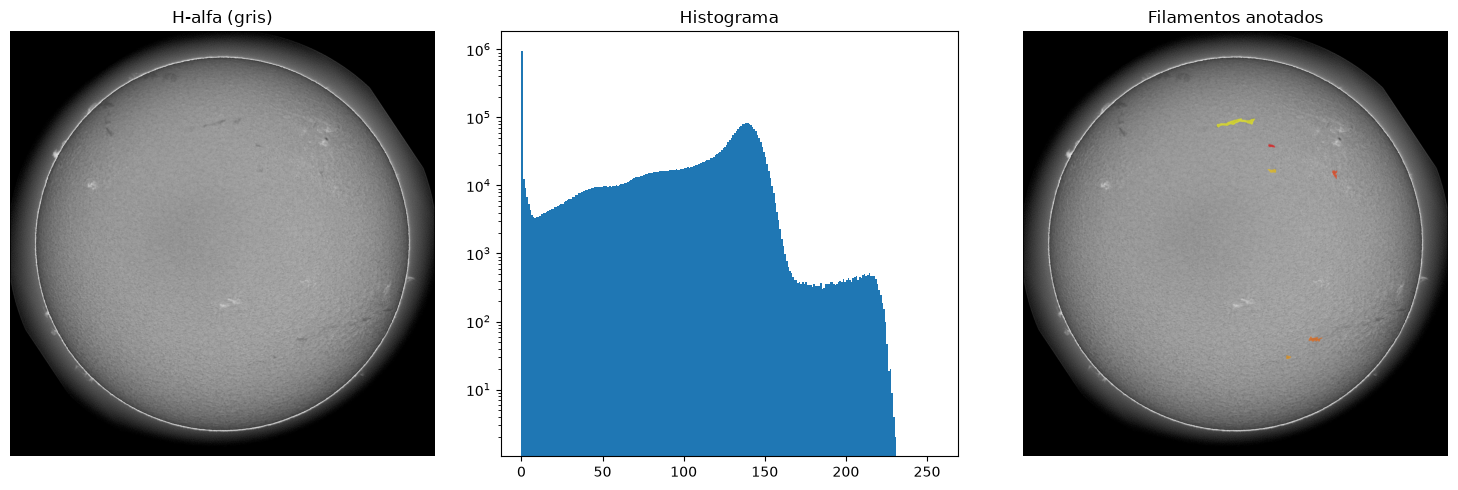

In [3]:
def leer_gris(ruta):
    # imdecode en lugar de imread: imread no abre rutas con tildes en Windows
    img = cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(ruta)
    return img

def etiquetas_reales(info_imagen):
    h, w = info_imagen['height'], info_imagen['width']
    lab = np.zeros((h, w), np.int32)
    for k, a in enumerate(anots_por_id[str(info_imagen['id'])], start=1):
        seg = a['segmentation']
        if isinstance(seg, dict):
            m = mask_utils.decode(mask_utils.frPyObjects(seg, h, w)) > 0
            lab[m] = k
        else:
            for poli in seg:
                pts = np.round(np.array(poli).reshape(-1, 2)).astype(np.int32)
                cv2.fillPoly(lab, [pts], k)
    return lab

ejemplo = primer_id_por_foto[fotos[0]]
gris = leer_gris(DIR_TRAIN / ejemplo['file_name'])
lab_real = etiquetas_reales(ejemplo)
print('Imagen:', ejemplo['file_name'], '| tamaño:', gris.shape, '| filamentos:', lab_real.max())

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(gris, cmap='gray'); ax[0].set_title('H-alfa (gris)')
ax[1].hist(gris.ravel(), bins=256, range=(0, 256)); ax[1].set_title('Histograma'); ax[1].set_yscale('log')
ax[2].imshow(gris, cmap='gray'); ax[2].imshow(np.ma.masked_equal(lab_real, 0), cmap='autumn', alpha=0.6)
ax[2].set_title('Filamentos anotados')
for a in (ax[0], ax[2]): a.axis('off')
plt.tight_layout(); plt.show()

El disco solar es más oscuro hacia el borde (oscurecimiento al limbo), por lo que un umbral global confunde el borde del disco con filamentos. Por esta razón, el método compara cada píxel con el brillo de su entorno en lugar de usar un valor fijo.

## 3. Método

1. **Disco solar:** umbral de Otsu y erosión, para descartar el fondo y el borde del disco.
2. **Fondo local:** mediana con ventana grande (calculada a media resolución por velocidad). Se usa el cociente entre la imagen y su fondo.
3. **Umbral relativo:** un píxel se marca si es más oscuro que su entorno en una proporción dada por `umbral_rel`.
4. **Morfología:** apertura y cierre con un elemento elíptico.
5. **Instancias:** componentes conectadas; se descartan las de área menor a `area_min`.

| Parámetro | Valor inicial | Justificación |
|---|---|---|
| `erosion_disco` | 41 px | Excluye el borde del disco, donde hay artefactos |
| `tam_fondo` | 101 px | Mucho mayor que el ancho típico de un filamento |
| `umbral_rel` | 0,85 | Se ajusta en la sección 5 |
| `k_morf` | 5 | Elemento pequeño, porque los filamentos son delgados |
| `area_min` | 150 px | Elimina detecciones de ruido |

Filamentos predichos: 2 | anotados: 6 | tiempo: 0.18 s


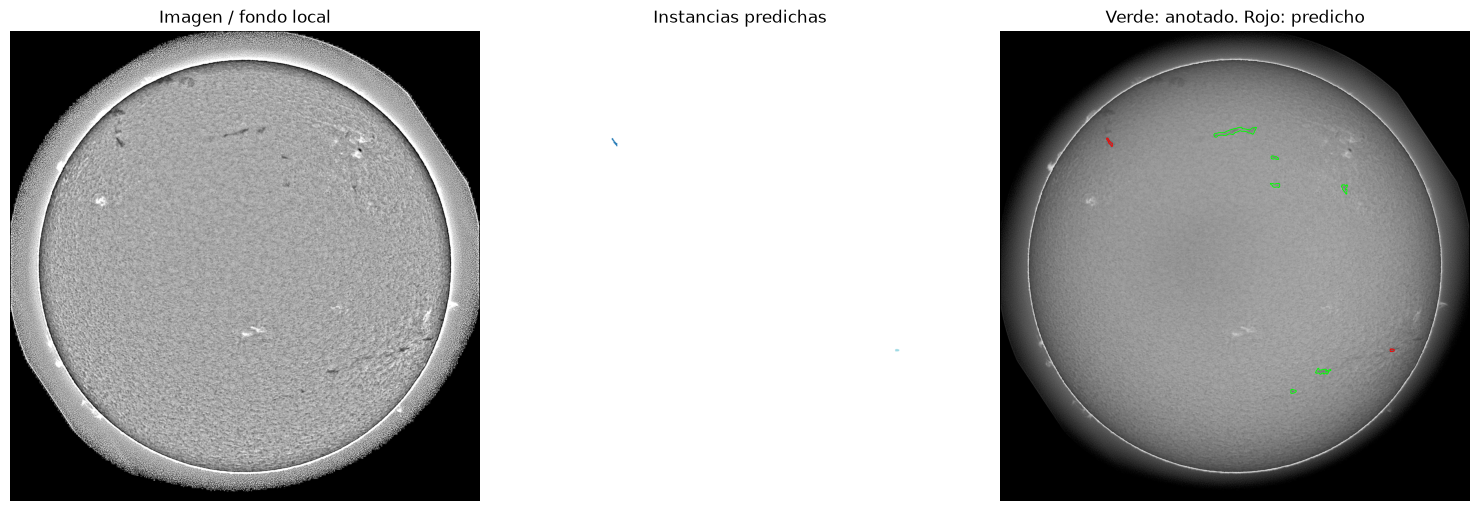

In [4]:
def segmentar_filamentos(gris, umbral_rel=0.85, tam_fondo=101, k_morf=5, area_min=150, erosion_disco=41):
    # 1. Disco solar
    _, disco = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    disco = cv2.erode(disco, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erosion_disco, erosion_disco)))

    # 2. Fondo local con mediana a media resolución (ventana impar)
    chico = cv2.resize(gris, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    fondo = cv2.medianBlur(chico, (tam_fondo // 2) | 1)
    fondo = cv2.resize(fondo, (gris.shape[1], gris.shape[0]), interpolation=cv2.INTER_LINEAR)
    relativo = gris.astype(np.float32) / (fondo.astype(np.float32) + 1.0)

    # 3. Umbral relativo dentro del disco
    mascara = ((relativo < umbral_rel) & (disco > 0)).astype(np.uint8) * 255

    # 4. Apertura y cierre
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_morf, k_morf))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, k)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, k)

    # 5. Componentes conectadas, sin las de área pequeña
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mascara, connectivity=8)
    grandes = np.zeros(n, np.int32)
    nuevo = 0
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= area_min:
            nuevo += 1
            grandes[i] = nuevo
    return grandes[lab], relativo

t0 = time.perf_counter()
lab_pred, relativo = segmentar_filamentos(gris)
print(f'Filamentos predichos: {lab_pred.max()} | anotados: {lab_real.max()} | tiempo: {time.perf_counter()-t0:.2f} s')

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(relativo, cmap='gray', vmin=0.6, vmax=1.2); ax[0].set_title('Imagen / fondo local')
ax[1].imshow(np.ma.masked_equal(lab_pred, 0), cmap='tab20'); ax[1].set_title('Instancias predichas')
ax[2].imshow(gris, cmap='gray')
ax[2].contour(lab_real > 0, colors='lime', linewidths=0.6)
ax[2].contour(lab_pred > 0, colors='red', linewidths=0.6)
ax[2].set_title('Verde: anotado. Rojo: predicho')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. Métricas

Sean A la máscara predicha y B la de referencia.

| Métrica | Definición |
|---|---|
| IoU | \|A ∩ B\| / \|A ∪ B\| |
| Dice | 2 \|A ∩ B\| / (\|A\| + \|B\|) |
| PQ | Σ IoU(TP) / (TP + 0,5 FP + 0,5 FN) |

Dice e IoU se calculan sobre la máscara completa de cada imagen. PQ compara filamento por filamento: un par predicho y anotado es un acierto (TP) si su IoU es mayor a 0,5. Los predichos sin pareja son FP y los anotados sin pareja son FN. Por eso PQ penaliza tanto la fragmentación como la fusión de filamentos.

In [5]:
def dice_iou(lab_pred, lab_real):
    a, b = lab_pred > 0, lab_real > 0
    inter = np.logical_and(a, b).sum()
    suma, union = a.sum() + b.sum(), np.logical_or(a, b).sum()
    dice = 1.0 if suma == 0 else 2 * inter / suma
    iou = 1.0 if union == 0 else inter / union
    return float(dice), float(iou)

def panoptic_quality(lab_pred, lab_real):
    ng, npred = int(lab_real.max()), int(lab_pred.max())
    if ng == 0 and npred == 0:
        return 1.0, 0, 0, 0
    # Matriz de intersecciones entre filamentos anotados (filas) y predichos (columnas)
    inter = np.bincount(lab_real.ravel() * (npred + 1) + lab_pred.ravel(),
                        minlength=(ng + 1) * (npred + 1)).reshape(ng + 1, npred + 1)
    area_g, area_p = inter.sum(1), inter.sum(0)
    union = area_g[:, None] + area_p[None, :] - inter
    iou = np.where(union > 0, inter / np.maximum(union, 1), 0)[1:, 1:]
    pares = iou > 0.5        # con IoU > 0,5 el emparejamiento es único
    tp = int(pares.sum())
    fp, fn = npred - tp, ng - tp
    pq = iou[pares].sum() / (tp + 0.5 * fp + 0.5 * fn) if (tp + fp + fn) else 1.0
    return float(pq), tp, fp, fn

d, i = dice_iou(lab_pred, lab_real)
pq, tp, fp, fn = panoptic_quality(lab_pred, lab_real)
print(f'Imagen de ejemplo: Dice={d:.3f} | IoU={i:.3f} | PQ={pq:.3f} (TP={tp}, FP={fp}, FN={fn})')

Imagen de ejemplo: Dice=0.000 | IoU=0.000 | PQ=0.000 (TP=0, FP=2, FN=6)


## 5. Ajuste del umbral relativo

Las imágenes de entrenamiento se dividen con una semilla fija en un grupo de ajuste, usado para elegir `umbral_rel`, y un grupo de validación, usado solo para reportar el resultado. El umbral se elige por PQ.

umbral_rel |  Dice  |  IoU   |  PQ


   0.80    | 0.056  | 0.031  | 0.000


   0.84    | 0.158  | 0.091  | 0.006


   0.87    | 0.299  | 0.185  | 0.024


   0.90    | 0.404  | 0.265  | 0.082


   0.92    | 0.475  | 0.320  | 0.097


   0.94    | 0.397  | 0.256  | 0.068

Umbral elegido (mejor PQ en ajuste): 0.92


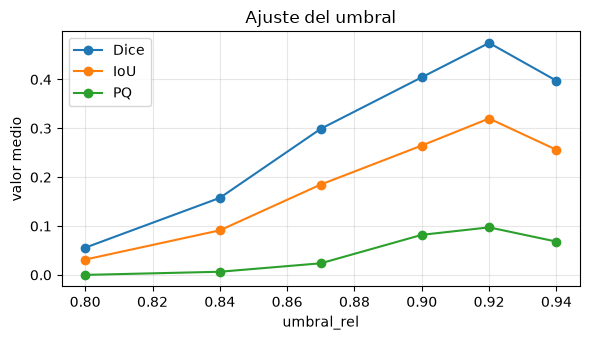

In [6]:
rng = np.random.default_rng(2026)
orden = rng.permutation(len(fotos))
N_AJUSTE = min(20, len(fotos) // 3)
N_VAL = min(40, len(fotos) - N_AJUSTE)
fotos_ajuste = [fotos[k] for k in orden[:N_AJUSTE]]
fotos_val = [fotos[k] for k in orden[N_AJUSTE:N_AJUSTE + N_VAL]]

cache = {}
def cargar(f):
    if f not in cache:
        info = primer_id_por_foto[f]
        cache[f] = (leer_gris(DIR_TRAIN / f), etiquetas_reales(info))
    return cache[f]

def evaluar(lista, **params):
    filas = []
    for f in lista:
        g, real = cargar(f)
        pred, _ = segmentar_filamentos(g, **params)
        d, i = dice_iou(pred, real)
        pq, tp, fp, fn = panoptic_quality(pred, real)
        filas.append((f, d, i, pq, tp, fp, fn))
    return filas

UMBRALES = [0.80, 0.84, 0.87, 0.90, 0.92, 0.94]
print('umbral_rel |  Dice  |  IoU   |  PQ')
resumen = {}
for u in UMBRALES:
    filas = evaluar(fotos_ajuste, umbral_rel=u)
    m = np.mean([r[1:4] for r in filas], axis=0)
    resumen[u] = m
    print(f'   {u:.2f}    | {m[0]:.3f}  | {m[1]:.3f}  | {m[2]:.3f}')

MEJOR_UMBRAL = max(resumen, key=lambda u: resumen[u][2])
print('\nUmbral elegido (mejor PQ en ajuste):', MEJOR_UMBRAL)

plt.figure(figsize=(6, 3.5))
for j, nombre in enumerate(['Dice', 'IoU', 'PQ']):
    plt.plot(UMBRALES, [resumen[u][j] for u in UMBRALES], marker='o', label=nombre)
plt.xlabel('umbral_rel'); plt.ylabel('valor medio'); plt.title('Ajuste del umbral'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(DIR_RESULTADOS / 'ajuste_umbral.png', dpi=150); plt.show()

## 6. Resultado en validación

Imágenes de validación: 40 | umbral_rel = 0.92
Dice medio = 0.513 (± 0.111)
IoU  medio = 0.352 (± 0.097)
PQ   medio = 0.090 (± 0.071)
Filamentos: TP=86  FP=816  FN=239


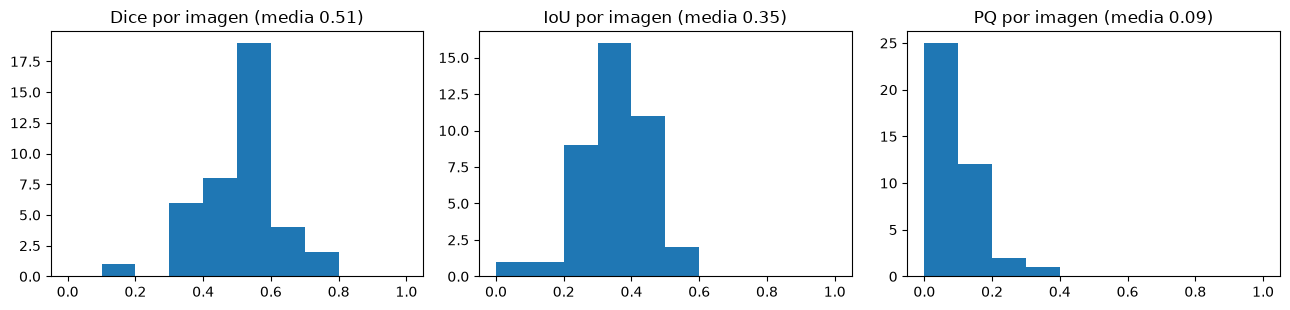

In [7]:
filas_val = evaluar(fotos_val, umbral_rel=MEJOR_UMBRAL)
D = np.array([r[1] for r in filas_val]); I = np.array([r[2] for r in filas_val]); P = np.array([r[3] for r in filas_val])
TP, FP, FN = (sum(r[k] for r in filas_val) for k in (4, 5, 6))

print(f'Imágenes de validación: {len(filas_val)} | umbral_rel = {MEJOR_UMBRAL}')
print(f'Dice medio = {D.mean():.3f} (± {D.std():.3f})')
print(f'IoU  medio = {I.mean():.3f} (± {I.std():.3f})')
print(f'PQ   medio = {P.mean():.3f} (± {P.std():.3f})')
print(f'Filamentos: TP={TP}  FP={FP}  FN={FN}')

with open(DIR_RESULTADOS / 'metricas_validacion.csv', 'w', newline='', encoding='utf-8') as fh:
    w = csv.writer(fh); w.writerow(['foto', 'dice', 'iou', 'pq', 'tp', 'fp', 'fn']); w.writerows(filas_val)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, v, n in zip(ax, (D, I, P), ('Dice', 'IoU', 'PQ')):
    a.hist(v, bins=10, range=(0, 1)); a.set_title(f'{n} por imagen (media {v.mean():.2f})')
plt.tight_layout(); plt.savefig(DIR_RESULTADOS / 'distribucion_metricas.png', dpi=150); plt.show()

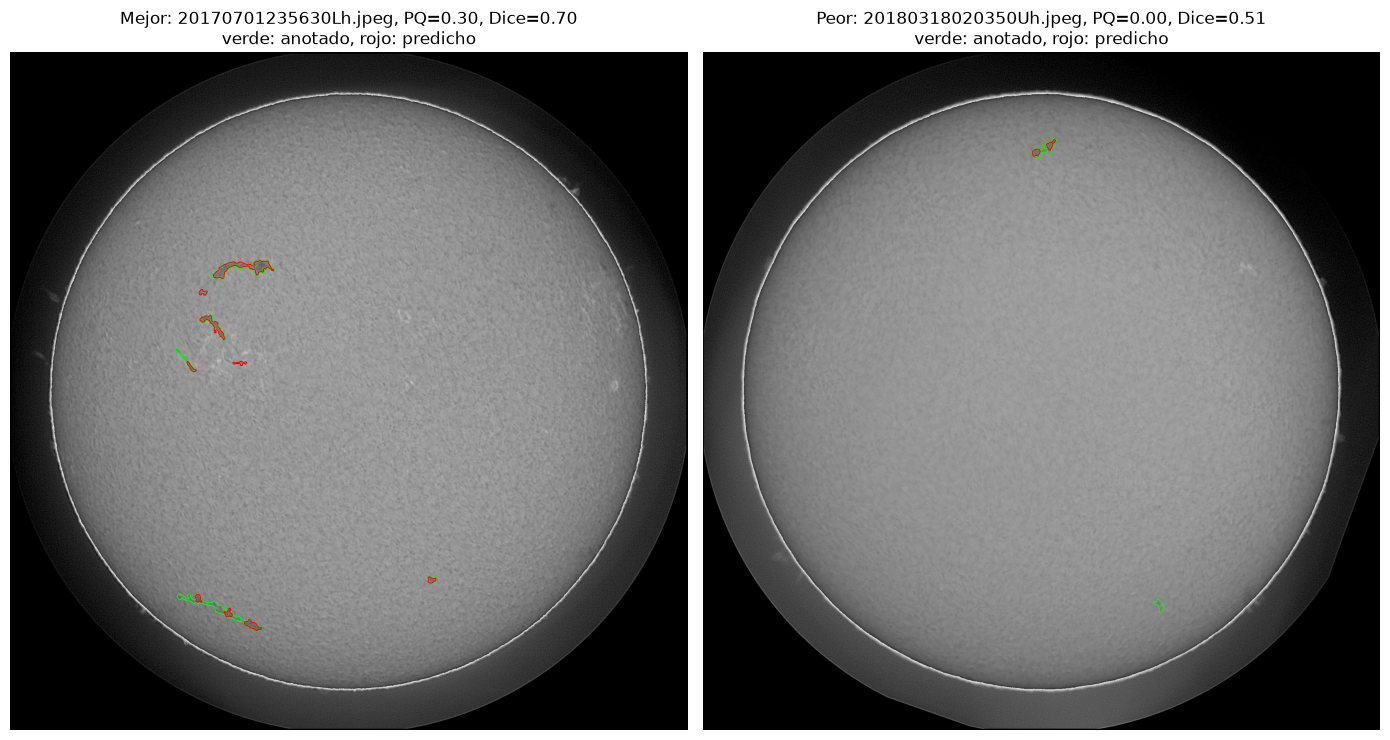

In [8]:
orden_pq = np.argsort(P)
fig, ax = plt.subplots(1, 2, figsize=(14, 7.4))
for a, idx, nombre in zip(ax, (orden_pq[-1], orden_pq[0]), ('Mejor', 'Peor')):
    f = filas_val[idx][0]
    g, real = cargar(f)
    pred, _ = segmentar_filamentos(g, umbral_rel=MEJOR_UMBRAL)
    a.imshow(g, cmap='gray')
    a.contour(real > 0, colors='lime', linewidths=0.6)
    a.contour(pred > 0, colors='red', linewidths=0.6)
    a.set_title(f'{nombre}: {f}, PQ={P[idx]:.2f}, Dice={D[idx]:.2f}\nverde: anotado, rojo: predicho')
    a.axis('off')
plt.tight_layout(); plt.savefig(DIR_RESULTADOS / 'mejor_y_peor.png', dpi=150, bbox_inches='tight'); plt.show()

### Observaciones

- El método ubica la mayoría de los filamentos (Dice medio cercano a 0,5), pero el PQ es bajo porque los filamentos largos se dividen en varios fragmentos. Cada fragmento tiene IoU menor a 0,5 con el filamento anotado, de modo que se cuenta como FP y el filamento como FN.
- Hay muchas detecciones pequeñas que no corresponden a filamentos (alrededor de 20 FP por imagen).
- Los filamentos de bajo contraste no se detectan.

## 7. Archivo de envío para Kaggle

Una fila por filamento: `filament_id` es el nombre de la imagen con un sufijo `_k`, y `segmentation_rle` es la máscara codificada en RLE con `pycocotools`.

In [9]:
filas_sub = []
for ruta in sorted(DIR_TEST.glob('*.jp*g')):
    pred, _ = segmentar_filamentos(leer_gris(ruta), umbral_rel=MEJOR_UMBRAL)
    for k in range(1, int(pred.max()) + 1):
        rle = mask_utils.encode(np.asfortranarray((pred == k).astype(np.uint8)))
        filas_sub.append((f'{ruta.stem}_{k}', rle['counts'].decode('ascii')))

with open(DIR_RESULTADOS / 'submission.csv', 'w', newline='', encoding='utf-8') as fh:
    w = csv.writer(fh); w.writerow(['filament_id', 'segmentation_rle']); w.writerows(filas_sub)
print('submission.csv:', len(filas_sub), 'filamentos en', len(list(DIR_TEST.glob('*.jp*g'))), 'imágenes de test')

submission.csv: 3743 filamentos en 180 imágenes de test


## 8. Trabajo siguiente

1. Entrenar una U-Net con las máscaras de entrenamiento y comparar contra este baseline.
2. Unir fragmentos de un mismo filamento mediante morfología orientada, para reducir FP y FN.
3. Filtrar detecciones pequeñas o redondeadas según su forma.